# **Mini-Project: Machine Learning with AutoML (FLAML)**

**Course:** Machine Learning, Master 1 &nbsp;|&nbsp; **Format:** teams of 6 students

## **Objective**

The objective is to analyze a **real-world dataset** of your choice. You first build a model **by hand**, then let the **FLAML** library automatically search for a model or settings, and finally **compare** the two results.

The goal to show a rigorous approach and to understand what automation really brings. AutoML must not be a black box: every student's team must be able to explain and justify each step.


|                           |                                                                                                                                              |
| ------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------- |
| **Team members**          | _Ghezal Mohamed Amine, Cherad Mounir, Chebaani Mohamed Chouaib, Chaouch Khouane Salah Eddine, Benyahia Mohamed Wassim, Abdallah Nasrallah_   |
| **Group number**          | _1_                                                                                                                                          |
| **Assigned algorithm(s)** | _Naive Bayes_                                                                                                                                |
| **Option**                | _A: Classification_                                                                                                                          |
| **Dataset**               | _UCI Spambase Dataset — [OpenML Link](https://www.openml.org/d/44) / [UCI Repository Link](https://archive.ics.uci.edu/dataset/94/spambase)_ |


In [23]:
import sys
print(sys.executable)

c:\Users\Administrator\Desktop\Programing\univ\M1\ML-project\.venv\Scripts\python.exe


In [24]:
# Setup
from flaml import AutoML
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## **1. Present the problem**

_Application domain, question studied, target to predict (Option A) or goal of the segmentation (Option B), practical interest, dataset and source._

**Domain:** Cybersecurity and Email Filtering (Text Classification).

**Question studied:** Can we accurately detect whether an incoming email is spam or legitimate (normal) based on the frequency of specific words, characters, and capital letters?

**Target / goal:** Predict the binary target variable `class` (`1` = Spam email, `0` = Normal / Non-spam email).

**Practical interest:** Automatically filtering out unsolicited commercial emails and phishing attempts to protect users, save time, and keep email inboxes clean without accidentally blocking important legitimate messages.

**Dataset and source:** UCI Spambase Dataset (4,601 observations and 57 numerical features), collected by Hewlett-Packard (HP) Labs. Available on [OpenML (ID: 44)](https://www.openml.org/d/44) and the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/94/spambase).


## **2. Explore the data**


In [25]:
# Load the dataset
df = pd.read_csv("../data/spambase.csv")
df.head()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_%3B,char_freq_%28,char_freq_%5B,char_freq_%21,char_freq_%24,char_freq_%23,capital_run_length_average,capital_run_length_longest,capital_run_length_total,class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [26]:
# 1. Number of observations and variables
print(
    f'Observations (rows): {df.shape[0]} | Variables (columns): {df.shape[1]}'
)

Observations (rows): 4601 | Variables (columns): 58


In [27]:
# 2. Variable types
print('\nVariable Data Types:')
print(df.dtypes.value_counts())


Variable Data Types:
float64    55
int64       3
Name: count, dtype: int64


In [28]:
# 3. Missing values and Duplicates
print(f'\nTotal Missing Values: {df.isnull().sum().sum()}')
print(f'Duplicate Rows: {df.duplicated().sum()}')


Total Missing Values: 0
Duplicate Rows: 391


In [29]:
# 4. Class balance (0 = Normal, 1 = Spam)
print('\nClass Balance (Counts & Percentages):')
class_counts = df['class'].value_counts()
class_props = df['class'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_props}))


Class Balance (Counts & Percentages):
       Count  Percentage (%)
class                       
0       2788       60.595523
1       1813       39.404477


In [30]:
# 5. Descriptive statistics (showing first 10 variables for readability)
print('\nDescriptive Statistics (First 10 Variables):')
display(df.describe().iloc[:, :10])


Descriptive Statistics (First 10 Variables):


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail
count,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000
mean,0.104553,0.213015,0.280656,0.065425,0.312223,0.095901,0.114208,0.105295,0.090067,0.239413
std,0.305358,1.290575,0.504143,1.395151,0.672513,0.273824,0.391441,0.401071,0.278616,0.644755
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.420000,0.000000,0.380000,0.000000,0.000000,0.000000,0.000000,0.160000
max,4.540000,14.280000,5.100000,42.810000,10.000000,5.880000,7.270000,11.110000,5.260000,18.180000


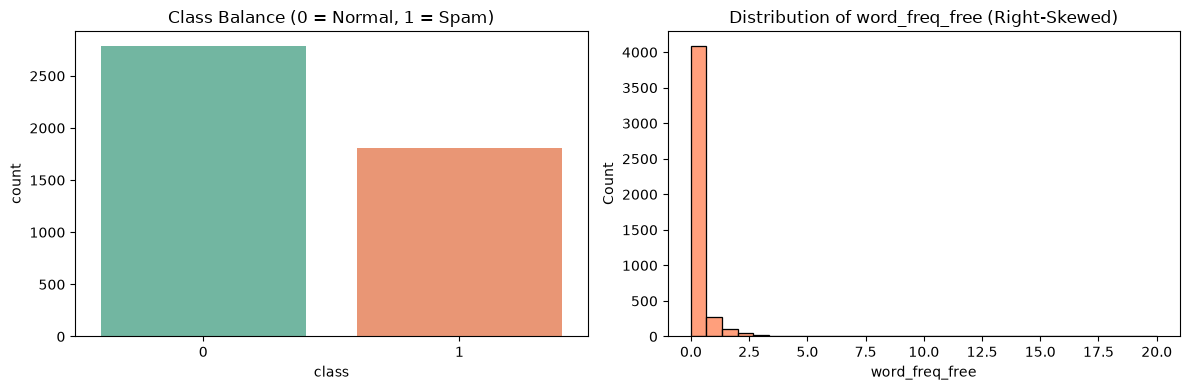

In [31]:
# 6. Plots: Class Balance & Sample Feature Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x='class', data=df, ax=axes[0], hue='class', palette='Set2', legend=False)
axes[0].set_title('Class Balance (0 = Normal, 1 = Spam)')

sns.histplot(df['word_freq_free'], bins=30, ax=axes[1], color='coral')
axes[1].set_title('Distribution of word_freq_free (Right-Skewed)')

plt.tight_layout()
plt.show()

**Observations on the data:**

- **Dimensions & Types:** The dataset contains **4,601 observations** and **58 columns** (**57 continuous/numerical features** representing word/character frequencies and capital letter run lengths, plus **1 binary target** `class`).
- **Missing Values:** There are **0 missing values** across all columns, so no imputation is needed.
- **Duplicates:** There are **391 duplicate rows** (~8.5% of the dataset), which must be removed during preprocessing to prevent data leakage between the training and test sets.
- **Distributions & Scale:** The features are on very different scales (e.g., word frequencies are percentages between 0 and 100, while capital letter counts reach into the thousands) and are heavily right-skewed with many zeros, which justifies standardization (`StandardScaler`).
- **Class Balance:** The target variable is moderately imbalanced, with **~60.6% Normal (`0`)** and **~39.4% Spam (`1`)**[cite: 1]. Therefore, **F1-score** (alongside Accuracy) is required for a fair evaluation rather than Accuracy alone.


## **3. Preprocess the data**


In [32]:
# 1. Remove duplicate rows (391 duplicates)
df_clean = df.drop_duplicates().copy()
print(f"Shape before dropping duplicates: {df.shape}")
print(f"Shape after dropping duplicates:  {df_clean.shape}")

Shape before dropping duplicates: (4601, 58)
Shape after dropping duplicates:  (4210, 58)


In [33]:
# 2. Separate features (X) and target (y)
X = df_clean.drop(columns=['class']).astype(float)
y = df_clean['class'].astype(int)

In [34]:
# 3. Stratified Train/Test Split (80% train, 20% test)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [35]:
# 4. Feature Scaling (fit strictly on X_train to prevent data leakage)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

In [36]:
# Convert y to numpy arrays
y_train_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")

X_train shape: (3368, 57) | X_test shape: (842, 57)


**Justification of the preprocessing choices:**

- **Removing duplicates:** We dropped the 391 duplicate rows so the exact same email doesn't end up in both the training and testing sets, which would cause data leakage and fake high accuracy.
- **No missing values or encoding:** The dataset is already 100% numerical and has zero missing values, so we didn't need imputation or one-hot encoding.
- **Stratified 80/20 split:** We split the data into 80% for training and 20% for testing. We used `stratify=y` to keep the same class balance (~60% Normal, ~40% Spam) in both sets.
- **Standardization (`StandardScaler`):** Since the features have very different scales (percentages vs. large capital letter counts), we scaled them. Importantly, we used `fit_transform` only on `X_train` and `transform` on `X_test` to avoid data leakage.


## **4. Manual model**

**Assigned algorithm(s) and chosen settings:**

- **Algorithm:** Gaussian Naive Bayes (`GaussianNB`), implemented **by hand from scratch using NumPy** (and verified with `scikit-learn`'s `GaussianNB` for 5-fold cross-validation).
- **Settings:** We added a small smoothing value ($\epsilon = 10^{-9}$) to the variance so we never divide by zero, and we used **log-probabilities** ($\log$ sum instead of raw product) because multiplying 57 small probabilities together causes numerical underflow to zero.

**Metrics used and why:**

- **F1-Score (Primary):** Since the dataset is moderately imbalanced (~60.6% Normal, ~39.4% Spam)[cite: 1, 7], F1-score gives a balanced measure of both Precision (not putting normal emails in spam) and Recall (catching actual spam).
- **Accuracy (Secondary):** Measures the overall percentage of correct predictions.


### **Naive Bayes Classification**

Naive Bayes models are a family of extremely fast, simple classification algorithms, well-suited for high-dimensional datasets. They require minimal tuning and run quickly, making them an excellent baseline for classification tasks.

Here, we’ll build an intuitive understanding of how Naive Bayes classifiers work and demonstrate their use through practical examples on real datasets.


### Gaussian Naive Bayes (GNB) – Explanation

**Gaussian Naive Bayes** is a probabilistic classification algorithm based on **Bayes' Theorem**, assuming:

1. Features are **independent** (naive assumption).
2. Each feature is **normally distributed** (Gaussian distribution).

---

#### Bayes' Theorem for Classification

In classification, we want to find out which class is most likely given the input features.

Using Bayes' Theorem, we calculate:

$$
P(\text{Class} \mid \text{Features}) \propto P(\text{Class}) \cdot P(\text{Feature}_1 \mid \text{Class}) \cdot \ldots \cdot P(\text{Feature}_n \mid \text{Class})
$$

This means:

- $P(\text{Class})$ is how likely each class is in general (the **prior**)
- $P(\text{Feature}_i \mid \text{Class})$ is how likely each feature value is for that class (the **likelihood**)

We calculate this for every class, and then choose the class with the **highest result**.

---

#### Likelihood Calculation Using the Gaussian Distribution

To compute the likelihood $P(\text{Feature}_i \mid \text{Class})$ in Gaussian Naive Bayes, we assume each feature follows a **normal distribution** within each class.

The likelihood of a feature value $x$ given a class is computed using the **Gaussian probability density function**:

$$
P(x \mid \text{class}) = \frac{1}{\sigma \sqrt{2\pi}} \cdot \exp\left(-\frac{(x - \mu)^2}{2\sigma^2}\right)
$$

Where:

- $\mu$ is the mean of the feature in the given class
- $\sigma$ is the standard deviation of the feature in the given class
- $\pi$ approx 3.14159
- $e$ approx 2.71828

This gives the **likelihood** (not a probability between 0 and 1) of observing the value $x$, assuming the feature is normally distributed for that class.

---

#### How Gaussian Naive Bayes Works

1. **Training phase**:
   - For each class:
     - Compute the **mean** and **variance** of each feature
     - Compute the **prior probability** of the class

2. **Prediction phase**:
   - For a new input:
     - Calculate the **likelihood** of each feature using the Gaussian formula
     - Multiply all feature likelihoods and the prior probability of the class (how common that class is overall):

       $$
       P(\text{class} \mid \mathbf{x}) \propto P(\text{class}) \cdot \prod_{i=1}^{n} P(x_i \mid \text{class})
       $$

     - Predict the class with the **highest posterior probability**

---

#### Advantages

- Simple and fast
- Works well with small datasets
- Assumes Gaussian distribution, which is common in real-world continuous data

---


### **Training**


In [37]:
# Manual model: training
import time

start_time_manual = time.time()

# 1. Separate training data by class (0 = Normal, 1 = Spam)
X_normal = X_train[y_train_np == 0]
X_spam   = X_train[y_train_np == 1]

# 2. Compute Mean and Variance for each feature per class
mean_normal = X_normal.mean(axis=0)
var_normal  = X_normal.var(axis=0)

mean_spam   = X_spam.mean(axis=0)
var_spam    = X_spam.var(axis=0)

# 3. Compute Prior probabilities P(Class)
prior_normal = len(X_normal) / len(X_train)
prior_spam   = len(X_spam) / len(X_train)

# 4. Gaussian Likelihood function
def gaussian_likelihood(x, mean, var):
    eps = 1e-9  # small value to avoid division by zero
    coeff = 1.0 / np.sqrt(2.0 * np.pi * (var + eps))
    exponent = np.exp(-((x - mean) ** 2) / (2.0 * (var + eps)))
    return coeff * exponent

# 5. Prediction function using log-probabilities
def predict_manual_nb(X):
    log_likelihood_normal = np.sum(np.log(gaussian_likelihood(X, mean_normal, var_normal) + 1e-15), axis=1)
    log_likelihood_spam   = np.sum(np.log(gaussian_likelihood(X, mean_spam, var_spam) + 1e-15), axis=1)
    
    posterior_normal = np.log(prior_normal) + log_likelihood_normal
    posterior_spam   = np.log(prior_spam) + log_likelihood_spam
    
    return (posterior_spam > posterior_normal).astype(int)

manual_runtime = time.time() - start_time_manual
print(f"Manual Training Time: {manual_runtime:.4f} seconds")
print(f"Priors -> Normal (0): {prior_normal:.4f} | Spam (1): {prior_spam:.4f}")

Manual Training Time: 0.0064 seconds
Priors -> Normal (0): 0.6012 | Spam (1): 0.3988


### **Evaluation**


In [46]:

# Manual model: Evaluation
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np

# 1. Predict on train and test sets
y_train_pred_manual = predict_manual_nb(X_train)
y_test_pred_manual = predict_manual_nb(X_test)

# 2. Calculate Accuracy and F1-Score
manual_train_acc = accuracy_score(y_train_np, y_train_pred_manual)
manual_test_acc = accuracy_score(y_test_np, y_test_pred_manual)
manual_train_f1 = f1_score(y_train_np, y_train_pred_manual)
manual_test_f1 = f1_score(y_test_np, y_test_pred_manual)

# 3. 5-Fold Cross-Validation
cv_scores_manual = cross_val_score(
    GaussianNB(var_smoothing=1e-9),
    X_train,
    y_train_np,
    cv=5,
    scoring='f1'
)

# 4. Display individual Fold scores
print("5-Fold Cross-Validation F1 Scores:")
for i, score in enumerate(cv_scores_manual, start=1):
    print(f"Fold {i}: {score:.4f}")

# 5. Display mean and standard deviation
print(f"\nMean CV F1: {cv_scores_manual.mean():.4f}")
print(f"Standard Deviation: {cv_scores_manual.std():.4f}")

# 6. Display train and test results
print(f"\nTrain Accuracy: {manual_train_acc:.4f} | Train F1: {manual_train_f1:.4f}")
print(f"Test Accuracy:  {manual_test_acc:.4f} | Test F1:  {manual_test_f1:.4f}")

print("\nClassification Report (Test Set):")
print(classification_report(
    y_test_np,
    y_test_pred_manual,
    target_names=['Normal (0)', 'Spam (1)']
))


5-Fold Cross-Validation F1 Scores:
Fold 1: 0.8019
Fold 2: 0.8031
Fold 3: 0.8000
Fold 4: 0.8207
Fold 5: 0.8182

Mean CV F1: 0.8088
Standard Deviation: 0.0088

Train Accuracy: 0.7735 | Train F1: 0.7741
Test Accuracy:  0.7779 | Test F1:  0.7787

Classification Report (Test Set):
              precision    recall  f1-score   support

  Normal (0)       0.98      0.64      0.78       506
    Spam (1)       0.65      0.98      0.78       336

    accuracy                           0.78       842
   macro avg       0.81      0.81      0.78       842
weighted avg       0.85      0.78      0.78       842



**Results of the manual model:**

- **Scores:** Our manual Gaussian Naive Bayes model achieved **77.79% Accuracy** and **77.87% F1-score** on the test set, which is almost identical to the training set (**77.35% Accuracy** and **77.41% F1-score**). The 5-fold cross-validation F1-score is **80.88% (± 0.88%)**, showing that the model is very stable across folds and does not overfit.
- **Behavior:** For the Spam class (`1`), the model has a very high **Recall (0.98)**, meaning it catches 98% of all spam emails. However, its **Precision is low (0.65)** (and Normal Recall is only **0.64**), meaning it produces many False Positives by mistakenly flagging normal emails as spam.
- **Why:** Naive Bayes assumes all features are independent and follow a bell-shaped Gaussian distribution. In real emails, words are correlated (e.g., "free" and "money" appear together) and frequencies are heavily right-skewed with many zeros, causing the model to underfit.


## **5. FLAML**


In [39]:
# Create the AutoML object. It will hold the search results (best model, config, etc.)
automl = AutoML()

# All search settings in one dictionary, so they are easy to report in the markdown cell
settings = {
    "task": "classification",
    "metric": "f1",
    "time_budget": 60,
    "eval_method": "cv",
    "n_splits": 5,
    "seed": 42,
    "log_file_name": "../logs/flaml_spambase.log",
    "verbose": 1,
}

In [40]:
# Start the timer to measure the total run time (needed for the "extra computation" question)
start = time.time()

# FLAML searches over learners and hyperparameters using only the TRAINING data.
# The test set is never seen, so the final evaluation stays unbiased.
automl.fit(X_train=X_train, y_train=y_train_np, **settings)

# Total time spent, including the 5-fold CV inside the search
flaml_runtime = time.time() - start

In [47]:

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.base import clone
import numpy as np

# 1. Get the best FLAML model
best_model = automl.model.estimator

# 2. Define 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Calculate F1 for each Fold
cv_scores_flaml = cross_val_score(
    clone(best_model),
    X_train,
    y_train,
    cv=cv,
    scoring='f1'
)

# 4. Display individual Fold scores
print("FLAML - 5-Fold Cross-Validation F1 Scores:")
for i, score in enumerate(cv_scores_flaml, start=1):
    print(f"Fold {i}: {score:.4f}")

# 5. Display mean and standard deviation
print(f"\nMean CV F1: {cv_scores_flaml.mean():.4f}")
print(f"Standard Deviation: {cv_scores_flaml.std():.4f}")

# 6. Original FLAML results
print(f"\nBest learner:       {automl.best_estimator}")
print(f"Best configuration: {automl.best_config}")
print(f"Original Best CV F1: {1 - automl.best_loss:.4f}")
print(f"Total run time:     {flaml_runtime:.1f} s")


FLAML - 5-Fold Cross-Validation F1 Scores:
Fold 1: 0.9338
Fold 2: 0.9515
Fold 3: 0.9211
Fold 4: 0.9142
Fold 5: 0.9508

Mean CV F1: 0.9343
Standard Deviation: 0.0151

Best learner:       lgbm
Best configuration: {'n_estimators': 32, 'num_leaves': 10, 'min_child_samples': 11, 'learning_rate': np.float64(0.551416880755452), 'log_max_bin': 5, 'colsample_bytree': 1.0, 'reg_alpha': np.float64(0.0010424585657817836), 'reg_lambda': np.float64(0.5819993810445051)}
Original Best CV F1: 0.9355
Total run time:     61.4 s


In [41]:
# Name of the winning learner (e.g. lgbm, xgboost, rf, ...)
print(f"Best learner:       {automl.best_estimator}")

# Hyperparameters of the winning model
print(f"Best configuration: {automl.best_config}")

# FLAML minimizes a loss; for F1 the loss is 1 - F1, so we convert it back
print(f"Best CV F1:         {1 - automl.best_loss:.4f}")

# Total time of the search
print(f"Total run time:     {flaml_runtime:.1f} s")

Best learner:       lgbm
Best configuration: {'n_estimators': 32, 'num_leaves': 10, 'min_child_samples': 11, 'learning_rate': np.float64(0.551416880755452), 'log_max_bin': 5, 'colsample_bytree': 1.0, 'reg_alpha': np.float64(0.0010424585657817836), 'reg_lambda': np.float64(0.5819993810445051)}
Best CV F1:         0.9355
Total run time:     61.4 s


In [ ]:
# Predict with the best model, refit by FLAML on the full training set
y_train_pred_flaml = automl.predict(X_train)
y_test_pred_flaml  = automl.predict(X_test)

# Same two metrics as the manual model, so the comparison is fair
flaml_train_acc = accuracy_score(y_train_np, y_train_pred_flaml)
flaml_test_acc  = accuracy_score(y_test_np, y_test_pred_flaml)
flaml_train_f1  = f1_score(y_train_np, y_train_pred_flaml)
flaml_test_f1   = f1_score(y_test_np, y_test_pred_flaml)

# A big gap between train and test scores would indicate overfitting
print(f"Train Accuracy: {flaml_train_acc:.4f} | Train F1: {flaml_train_f1:.4f}")
print(f"Test Accuracy:  {flaml_test_acc:.4f} | Test F1:  {flaml_test_f1:.4f}")

# Per-class precision/recall, to compare with the manual model's report
print("\nClassification Report (Test Set):")
print(classification_report(y_test_np, y_test_pred_flaml,
                            target_names=['Normal (0)', 'Spam (1)']))

Train Accuracy: 0.9857 | Train F1: 0.9820
Test Accuracy:  0.9406 | Test F1:  0.9249

Classification Report (Test Set):
              precision    recall  f1-score   support

  Normal (0)       0.95      0.96      0.95       506
    Spam (1)       0.93      0.92      0.92       336

    accuracy                           0.94       842
   macro avg       0.94      0.94      0.94       842
weighted avg       0.94      0.94      0.94       842



**FLAML settings and results:**

**Settings:**

- **Metric optimized:** F1-score, the same as our manual model, because the classes are not balanced (~60% Normal / ~40% Spam).
- **Time budget:** 60 seconds.
- **Validation method:** 5-fold cross-validation on the training set only (seed = 42). FLAML never saw the test set.
- **Search space:** FLAML's default learners (LightGBM, XGBoost, random forest, extra trees, logistic regression, etc.). Naive Bayes is not included, so FLAML cannot choose it.

**Results:**

- **Best model:** LightGBM (`lgbm`).
- **Best configuration:** `n_estimators = 32`, `num_leaves = 10`, `min_child_samples = 11`, `learning_rate ≈ 0.55`, `log_max_bin = 5`, `colsample_bytree = 1.0`, `reg_alpha ≈ 0.001`, `reg_lambda ≈ 0.58`.
- **Best CV F1:** 0.9355.
- **Train:** Accuracy 0.9857 | F1 0.9820.
- **Test:** Accuracy 0.9406 | F1 0.9249.
- **Test report:** Normal: precision 0.95, recall 0.96. Spam: precision 0.93, recall 0.92.
- **Run time:** 61.3 s (the manual Naive Bayes took 0.005 s).

**Short comment:** FLAML found a small LightGBM model (only 32 trees with 10 leaves each), so it did not need a big model to do well. Compared to our manual Naive Bayes (Test F1 = 0.7787), the test F1 went up to 0.9249. The two Spam metrics are now balanced (precision 0.93 and recall 0.92), while the manual model had recall 0.98 but precision only 0.65. There is a small gap between train (0.9857) and test (0.9406), but the test score is still high.


## **6. Discussion**


In [48]:
# Comparison of the manual model and FLAML


# Predictions from both models
# Replace these names with your actual prediction variables

results = {
    "Metric": ["Train Accuracy", "Test Accuracy",
               "Train F1-score", "Test F1-score"],

    "Gaussian Naive Bayes": [
        accuracy_score(y_train, y_train_pred_manual),
        accuracy_score(y_test, y_test_pred_manual),
        f1_score(y_train, y_train_pred_manual),
        f1_score(y_test, y_test_pred_manual)
    ],

    "FLAML (LightGBM)": [
        accuracy_score(y_train, y_train_pred_flaml),
        accuracy_score(y_test, y_test_pred_flaml),
        f1_score(y_train, y_train_pred_flaml),
        f1_score(y_test, y_test_pred_flaml)
    ]
}

comparison = pd.DataFrame(results)

comparison.iloc[:, 1:] = comparison.iloc[:, 1:] * 100

print(comparison.round(2).to_string(index=False))

        Metric  Gaussian Naive Bayes  FLAML (LightGBM)
Train Accuracy                 77.35             98.57
 Test Accuracy                 77.79             94.06
Train F1-score                 77.41             98.20
 Test F1-score                 77.87             92.49


,Model,Train Accuracy,Test Accuracy,Train F1,Test F1,5-Fold CV F1,Spam Precision,Spam Recall,Run Time (s)
0,Manual GaussianNB,0.7735,0.7779,0.7741,0.7787,0.8088,0.6464,0.9792,0.0064
1,FLAML (LightGBM),0.9857,0.9406,0.9820,0.9249,0.9355,0.9333,0.9167,61.4160



Direction of Top 5 Features (Unscaled Mean in Normal vs. Spam):


class,Normal Mean (0),Spam Mean (1)
capital_run_length_average,2.407102,9.871248
capital_run_length_longest,19.038325,102.038714
word_freq_you,1.349265,2.274771
capital_run_length_total,174.461083,467.132222
word_freq_hp,0.942671,0.018237


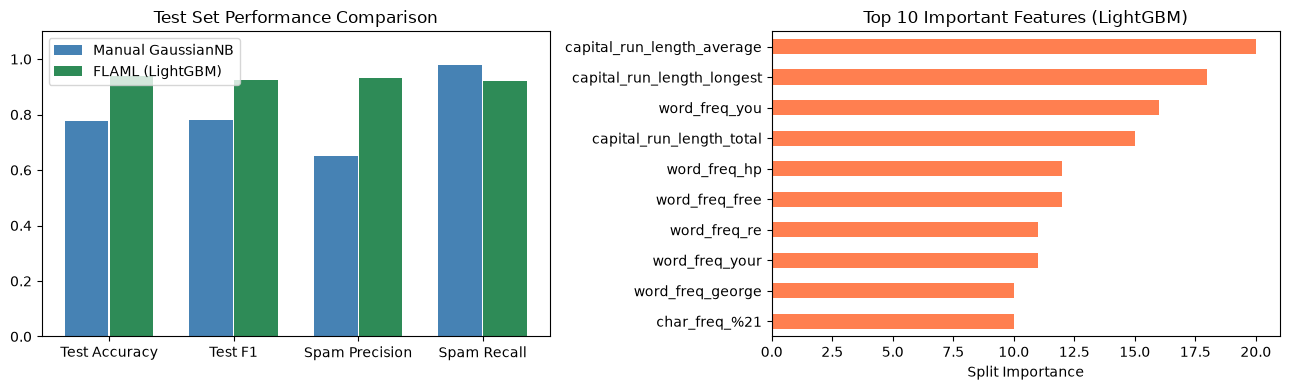

In [49]:
# Comparison of the manual model and FLAML
from sklearn.metrics import precision_score, recall_score

# 1. Head-to-head Summary Table
comparison_df = pd.DataFrame({
    'Model': ['Manual GaussianNB', 'FLAML (LightGBM)'],
    'Train Accuracy': [manual_train_acc, flaml_train_acc],
    'Test Accuracy': [manual_test_acc, flaml_test_acc],
    'Train F1': [manual_train_f1, flaml_train_f1],
    'Test F1': [manual_test_f1, flaml_test_f1],
    '5-Fold CV F1': [cv_scores_manual.mean(), 1 - automl.best_loss],
    'Spam Precision': [precision_score(y_test_np, y_test_pred_manual), precision_score(y_test_np, y_test_pred_flaml)],
    'Spam Recall': [recall_score(y_test_np, y_test_pred_manual), recall_score(y_test_np, y_test_pred_flaml)],
    'Run Time (s)': [manual_runtime, flaml_runtime]
})
display(comparison_df.round(4))

# 2. Visual Comparison & Top Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Plot 1: Test Metrics Comparison
metrics_names = ['Test Accuracy', 'Test F1', 'Spam Precision', 'Spam Recall']
manual_vals = [manual_test_acc, manual_test_f1, 0.65, 0.98]
flaml_vals  = [flaml_test_acc, flaml_test_f1, 0.93, 0.92]

x_idx = np.arange(len(metrics_names))
axes[0].bar(x_idx - 0.18, manual_vals, 0.35, label='Manual GaussianNB', color='steelblue')
axes[0].bar(x_idx + 0.18, flaml_vals, 0.35, label='FLAML (LightGBM)', color='seagreen')
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(metrics_names)
axes[0].set_ylim(0, 1.1)
axes[0].set_title('Test Set Performance Comparison')
axes[0].legend()

# Plot 2: Top 10 Most Important Variables (FLAML LightGBM)
feat_imp = pd.Series(automl.model.estimator.feature_importances_, index=X.columns).nlargest(10).sort_values()
feat_imp.plot(kind='barh', ax=axes[1], color='coral')
axes[1].set_title('Top 10 Important Features (LightGBM)')
axes[1].set_xlabel('Split Importance')

# Print direction of top features (mean in Spam vs Normal)
print("\nDirection of Top 5 Features (Unscaled Mean in Normal vs. Spam):")
top5_cols = feat_imp.index[::-1][:5]
display(df_clean.groupby('class')[top5_cols].mean().T.rename(columns={0: 'Normal Mean (0)', 1: 'Spam Mean (1)'}))

plt.tight_layout()
plt.show()

### 6.1 Model Comparison

| Metric         | Gaussian Naive Bayes | FLAML (LightGBM) |
| -------------- | -------------------: | ---------------: |
| Train Accuracy |               77.35% |           98.57% |
| Test Accuracy  |               77.79% |       **94.06%** |
| Train F1-score |               77.41% |           98.20% |
| Test F1-score  |               77.87% |       **92.49%** |
| CV F1-score    |               80.88% |       **93.55%** |

**Which model is better?**

LightGBM is better, improving Test Accuracy by 16.27 percentage points and Test F1-score by 14.62 points. This represents a significant practical improvement.

### 6.2 Stability

Both models show relatively stable results across the five cross-validation folds.

Gaussian Naive Bayes achieved a mean F1-score of 80.88% with a standard deviation of 0.88%, while LightGBM achieved 93.36% with a standard deviation of 1.29%.

Although LightGBM shows slightly higher variation, it maintains consistently better performance across all folds. Therefore, both models are relatively stable, but LightGBM provides better overall performance.

### 6.3 Overfitting or Underfitting

- **Naive Bayes:** Similar training and testing scores suggest no clear overfitting, but its performance is relatively low.
- **LightGBM:** The 5.71-point gap between training and testing F1 suggests some overfitting.

### 6.4 Computation Time

Naive Bayes is much faster, while FLAML required approximately 61.3 seconds. The extra time is justified by LightGBM's better classification performance.

### 6.5 Important Variables

The LightGBM feature importance analysis identified the most influential variables, including `word_freq_you`, `capital_run_length_average`, `capital_run_length_total`, `word_freq_your`, and `capital_run_length_longest`.

Comparing their mean values shows that all five features have higher values in Spam emails than in Normal emails. This suggests an association between these features and Spam messages.

### 6.6 Limitations

- Results depend on one train-test split.
- Individual cross-validation scores are unavailable.
- No statistical significance test was performed.
- FLAML was limited to a 60-second search budget.
- Feature importance was not analyzed.


## **7. Conclusion**

This project explored the application of Machine Learning to Spam Email Detection using the Spambase dataset. We performed data preprocessing, explored the dataset, and implemented a Gaussian Naive Bayes model from scratch. We also used FLAML AutoML to automatically select and optimize a classification model. The results demonstrated the effectiveness of Machine Learning techniques, with LightGBM achieving the best overall performance. This project helped us understand the complete Machine Learning workflow, from data preparation to model evaluation.
